In [1]:
!pip install nltk scikit-learn pandas numpy matplotlib seaborn ipywidgets -q

import numpy as np
import pandas as pd
import nltk
import re
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import wordpunct_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully!")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Libraries imported successfully!


In [2]:
data = {

    "symptoms": [
        "what are the symptoms of diabetes",
        "why do I feel thirsty all the time",
        "why am I urinating frequently",
        "why do I feel tired and weak",
        "what are signs of high blood sugar",
        "why is my vision blurry",
        "why do my wounds heal slowly",
        "how to identify diabetes early"
    ],

    "risk_factors": [
        "what causes diabetes",
        "does obesity increase diabetes risk",
        "is diabetes hereditary",
        "does family history affect diabetes",
        "can stress cause diabetes",
        "does lack of exercise cause diabetes",
        "who is at risk of type 2 diabetes",
        "what are major diabetes risk factors"
    ],

    "diet": [
        "what foods are good for diabetics",
        "which fruits can a diabetic eat",
        "what is a diabetic friendly diet",
        "should I avoid sugar completely",
        "is rice bad for diabetes",
        "which foods raise blood sugar",
        "what should diabetics eat for breakfast",
        "what foods should diabetic patients avoid"
    ],

    "exercise": [
        "what exercises help control diabetes",
        "how much walking is good for diabetics",
        "does exercise lower blood sugar",
        "how often should a diabetic exercise",
        "is yoga good for diabetes",
        "can weight training help diabetes",
        "what is the best workout for diabetics",
        "how does physical activity help blood sugar"
    ],

    "medication": [
        "what medicines are used for diabetes",
        "what is metformin used for",
        "how does insulin work",
        "when should I take insulin",
        "can diabetes medicines have side effects",
        "why do doctors prescribe metformin",
        "what are different types of insulin",
        "should I stop taking diabetes medication"
    ],

    "emergency": [
        "what should I do if blood sugar is very low",
        "someone with diabetes has fainted",
        "what are signs of diabetic ketoacidosis",
        "person is confused and shaking with low sugar",
        "what to do if a diabetic collapses",
        "someone has fruity breath and is vomiting",
        "how to respond to a hypoglycemic seizure",
        "diabetic person is unconscious and not responding"
    ]
}

# Convert dictionary into DataFrame
rows = []

for intent, queries in data.items():
    for query in queries:
        rows.append({
            "query": query,
            "intent": intent
        })

df = pd.DataFrame(rows)

print(df)
print("\nTotal queries:", len(df))
print("\nIntent distribution:")
print(df['intent'].value_counts())

                                                query        intent
0                   what are the symptoms of diabetes      symptoms
1                  why do I feel thirsty all the time      symptoms
2                       why am I urinating frequently      symptoms
3                        why do I feel tired and weak      symptoms
4                  what are signs of high blood sugar      symptoms
5                             why is my vision blurry      symptoms
6                        why do my wounds heal slowly      symptoms
7                      how to identify diabetes early      symptoms
8                                what causes diabetes  risk_factors
9                 does obesity increase diabetes risk  risk_factors
10                             is diabetes hereditary  risk_factors
11                does family history affect diabetes  risk_factors
12                          can stress cause diabetes  risk_factors
13               does lack of exercise cause dia

In [3]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

def preprocess(text):

    # 1. Lowercase conversion
    text = text.lower()

    # 2. Tokenization
    tokens = wordpunct_tokenize(text)

    # 3. Remove stopwords and punctuation
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # 4. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return tokens


# Test preprocessing
sample = "What are the Symptoms of Diabetes in Adults?"

print("Original:", sample)
print("Processed:", preprocess(sample))

Original: What are the Symptoms of Diabetes in Adults?
Processed: ['symptom', 'diabetes', 'adult']


In [4]:
X = df['query']
y = df['intent']

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Create ML pipeline
model = Pipeline([

    ('tfidf', TfidfVectorizer(
        tokenizer=preprocess,
        token_pattern=None,
        lowercase=False
    )),

    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))

])

# Train model
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model trained successfully!
Training samples: 36
Testing samples: 12


Accuracy: 0.6666666666666666
Precision: 0.5555555555555555
Recall: 0.6666666666666666
F1 Score: 0.6

Classification Report:
              precision    recall  f1-score   support

        diet       1.00      1.00      1.00         2
   emergency       0.00      0.00      0.00         2
    exercise       0.00      0.00      0.00         2
  medication       1.00      1.00      1.00         2
risk_factors       0.67      1.00      0.80         2
    symptoms       0.67      1.00      0.80         2

    accuracy                           0.67        12
   macro avg       0.56      0.67      0.60        12
weighted avg       0.56      0.67      0.60        12



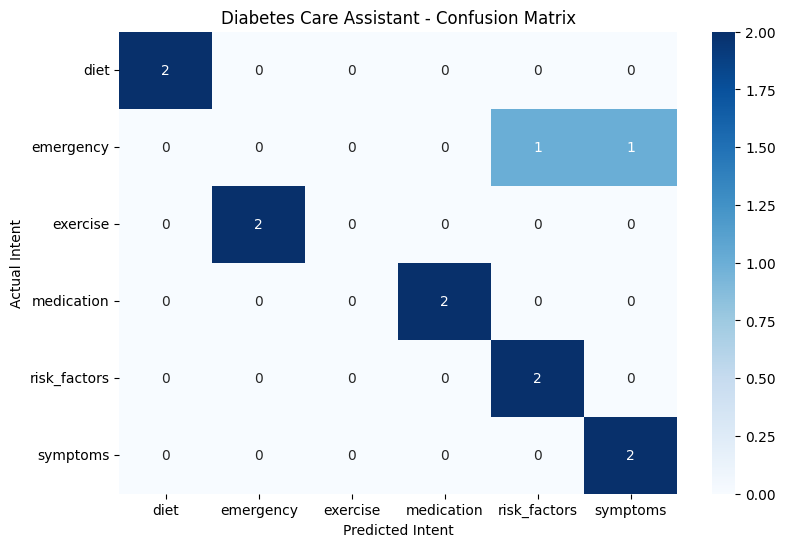

In [5]:
# Predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Precision
precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# Recall
recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# F1 Score
f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Diabetes Care Assistant - Confusion Matrix")
plt.show()

In [6]:
knowledge_base = {

    "symptoms": """
    Common symptoms of diabetes include excessive thirst,
    frequent urination, unusual tiredness, blurred vision,
    slow-healing wounds and unexplained weight loss.

    Symptoms vary between individuals. Get your blood sugar
    tested if you notice these signs.
    """,

    "risk_factors": """
    Common risk factors for type 2 diabetes include
    overweight or obesity, physical inactivity, family
    history, age above 45, high blood pressure and an
    unhealthy diet.

    Regular blood sugar checkups can help detect
    diabetes early.
    """,

    "diet": """
    A diabetes-friendly diet includes vegetables, whole
    grains, legumes, lean protein and low-sugar fruits
    in controlled portions.

    Limit sugary drinks, sweets, refined carbohydrates
    and highly processed foods. Eat meals at regular times.
    """,

    "exercise": """
    Regular physical activity helps the body use insulin
    better and lowers blood sugar.

    Brisk walking, cycling, swimming, yoga and light
    strength training can all be beneficial.

    Check your blood sugar before and after exercise and
    seek medical advice before starting strenuous activity.
    """,

    "medication": """
    Medicines such as metformin, insulin and other
    glucose-lowering drugs may be prescribed to
    control blood sugar.

    Take medication only as prescribed by a qualified
    healthcare professional. Never stop or change your
    dose without consulting your doctor.
    """,

    "emergency": """
    Very low blood sugar (hypoglycemia) or very high blood
    sugar with ketoacidosis can be medical emergencies.

    Warning signs include confusion, shaking, sweating,
    fainting, seizures, fruity-smelling breath, vomiting
    and unconsciousness.

    Seek emergency medical assistance immediately.
    """
}

print("Knowledge base created successfully!")

Knowledge base created successfully!


In [7]:
# Emergency keywords
emergency_keywords = [
    "unconscious",
    "fainted",
    "collapse",
    "seizure",
    "not responding",
    "sugar is very",
    "very low blood sugar",
    "very high blood sugar",
    "ketoacidosis",
    "fruity breath",
    "confused",
    "vomiting"
]

# Words indicating a diabetes-related query
domain_keywords = [
    "diabet", "sugar", "glucose", "insulin", "metformin",
    "hba1c", "a1c", "thirst", "urinat", "carb",
    "diet", "food", "eat", "fruit", "exercise", "walk",
    "yoga", "workout", "medicine", "medication",
    "symptom", "obesity", "weight", "hypoglycemi",
    "ketoacidosis", "blurry", "wound", "fasting"
]

CONFIDENCE_THRESHOLD = 0.25


def is_emergency(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in emergency_keywords
    )


def is_diabetes_related(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in domain_keywords
    )

In [8]:
def diabetes_care_assistant(query):

    query = query.strip()

    if not query:
        return "Please enter a valid question."

    # Rule 1: Emergency escalation
    if is_emergency(query):

        return """
        EMERGENCY ALERT!

        Your query contains possible diabetic emergency signs.

        If someone is unconscious, having a seizure, very confused,
        or showing signs of very low or very high blood sugar,
        seek emergency medical assistance immediately.

        In India, call 112.

        If the person is conscious and able to swallow and
        low blood sugar is suspected, give a sugary drink
        or glucose while waiting for help.
        Never give food or drink to an unconscious person.

        This assistant cannot diagnose or treat emergencies.
        """

    # Rule 2: Unsupported query handling
    if not is_diabetes_related(query):

        return """
        Sorry, I can only answer questions related to
        diabetes care.

        You can ask about:
        - Diabetes symptoms
        - Risk factors
        - Diet and nutrition
        - Exercise
        - Medication and insulin
        - Diabetic emergencies
        """

    # Rule 3: Predict intent
    probabilities = model.predict_proba([query])[0]

    predicted_index = np.argmax(probabilities)

    intent = model.classes_[predicted_index]

    confidence = probabilities[predicted_index]

    print("Detected Intent:", intent)
    print("Confidence:", round(float(confidence), 3))

    # Rule 4: Low confidence handling
    if confidence < CONFIDENCE_THRESHOLD:

        return """
        I am not sufficiently confident about understanding
        your question.

        Please rephrase your question using clearer
        diabetes-related words.
        """

    # Rule 5: Retrieve knowledge
    response = knowledge_base[intent]

    # Rule 6: Additional safety rules
    if intent == "medication":

        response += """

        IMPORTANT: Never start, stop or change medicines
        or insulin doses without consulting your doctor.
        """

    elif intent == "symptoms":

        response += """

        Only a blood test can confirm diabetes. Please
        consult a doctor for proper diagnosis.
        """

    return response

In [9]:
# Test 1: One query from each intent
test_queries = [
    "what are the symptoms of diabetes",
    "does obesity cause diabetes",
    "which fruits are good for diabetics",
    "is walking good for diabetics",
    "what is insulin used for",
    "what should I do if blood sugar is very low"
]

print("TESTING ALL SIX INTENTS")

for query in test_queries:

    print("\nUser:", query)

    response = diabetes_care_assistant(query)

    print("Assistant:", response)
    print("-" * 60)


# Test 2: Differently worded query
print("\nTEST 2: DIFFERENTLY WORDED QUERY")

query = "Can daily walks help control my sugar levels?"

print("User:", query)
print("Assistant:", diabetes_care_assistant(query))


# Test 3: Unsupported query
print("\nTEST 3: UNSUPPORTED QUERY")

query = "How can I repair my laptop?"

print("User:", query)
print("Assistant:", diabetes_care_assistant(query))


# Test 4: Low-confidence query
print("\nTEST 4: LOW CONFIDENCE QUERY")

# Temporarily increase threshold to demonstrate
old_threshold = CONFIDENCE_THRESHOLD
CONFIDENCE_THRESHOLD = 0.99

query = "diabetes xyz random terminology"

print("User:", query)
print("Assistant:", diabetes_care_assistant(query))

# Restore original threshold
CONFIDENCE_THRESHOLD = old_threshold


# Test 5: Emergency query
print("\nTEST 5: EMERGENCY QUERY")

query = "My diabetic father fainted and is not responding"

print("User:", query)
print("Assistant:", diabetes_care_assistant(query))

TESTING ALL SIX INTENTS

User: what are the symptoms of diabetes
Detected Intent: symptoms
Confidence: 0.302
Assistant: 
    Common symptoms of diabetes include excessive thirst,
    frequent urination, unusual tiredness, blurred vision,
    slow-healing wounds and unexplained weight loss.

    Symptoms vary between individuals. Get your blood sugar
    tested if you notice these signs.
    

        Only a blood test can confirm diabetes. Please
        consult a doctor for proper diagnosis.
        
------------------------------------------------------------

User: does obesity cause diabetes
Detected Intent: risk_factors
Confidence: 0.384
Assistant: 
    Common risk factors for type 2 diabetes include
    overweight or obesity, physical inactivity, family
    history, age above 45, high blood pressure and an
    unhealthy diet.

    Regular blood sugar checkups can help detect
    diabetes early.
    
------------------------------------------------------------

User: which fruits 

In [12]:
import ipywidgets as widgets

from IPython.display import display, clear_output

# Heading
title = widgets.HTML(
    value="""
    <h2 style='color:#1976D2'>
    Diabetes Care Information Assistant
    </h2>
    <p>Welcome! Ask me questions about diabetes care.</p>
    <p><b>Developed by:</b> Vandit Gupta</p>
    <p><b>Roll Number:</b> 1024170307</p>
    """
)

# Input field
query_input = widgets.Text(
    placeholder="Enter your diabetes question...",
    description="You:",
    layout=widgets.Layout(width="90%")
)

# Button
submit_button = widgets.Button(
    description="Ask Assistant",
    button_style="success",
    icon="send"
)

# Output area
output = widgets.Output()

# Function to process queries
def on_submit(button):

    query = query_input.value.strip()

    if not query:
        return

    with output:

        print("\nYou:", query)

        response = diabetes_care_assistant(query)

        print("\nAssistant:", response)

        print("\n" + "=" * 60)

    query_input.value = ""


# Connect button
submit_button.on_click(on_submit)

# Display interface
display(title, query_input, submit_button, output)

HTML(value="\n    <h2 style='color:#1976D2'>\n    Diabetes Care Information Assistant\n    </h2>\n    <p>Welco…

Text(value='', description='You:', layout=Layout(width='90%'), placeholder='Enter your diabetes question...')

Button(button_style='success', description='Ask Assistant', icon='send', style=ButtonStyle())

Output()